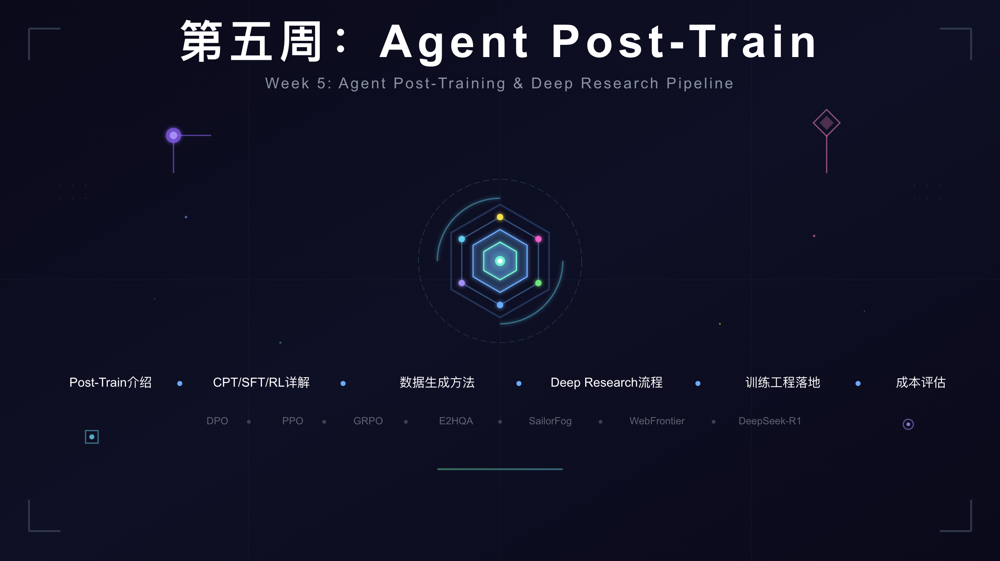

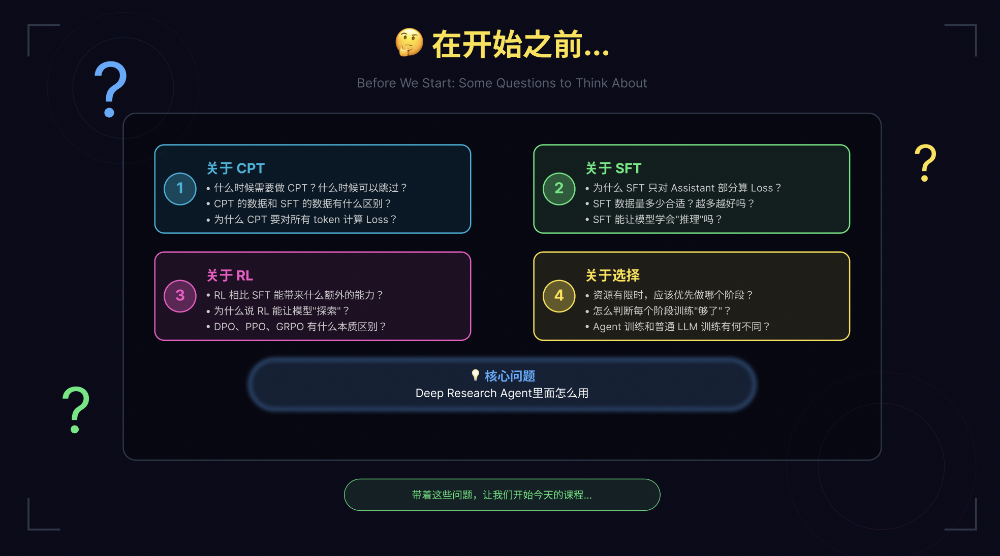

# Post-Train概览

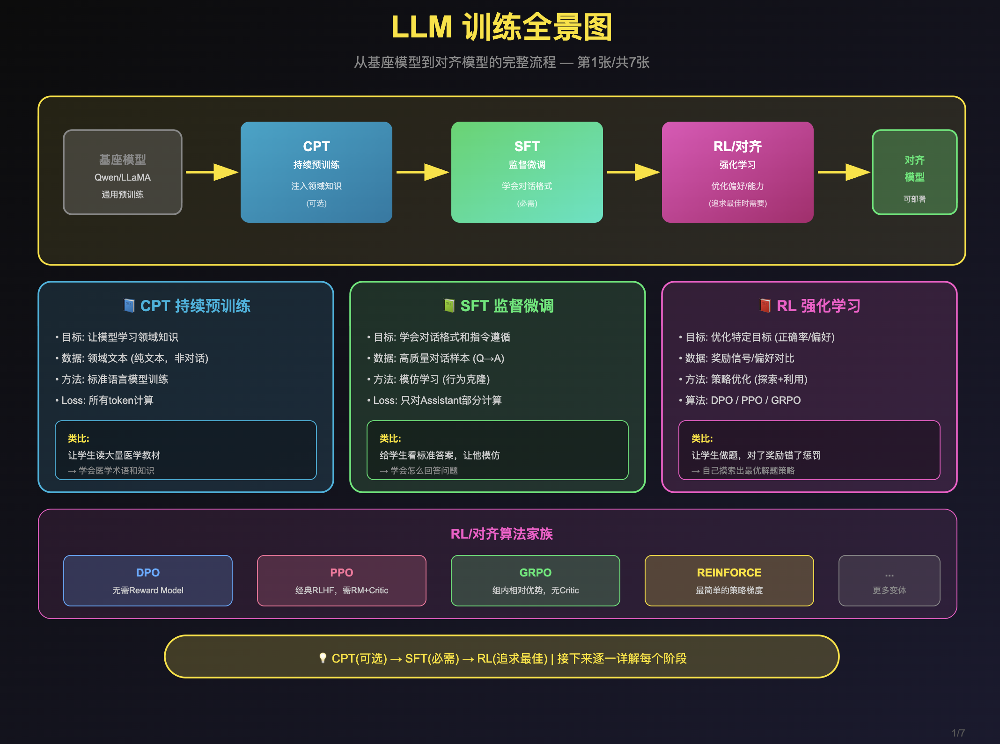

# CPT

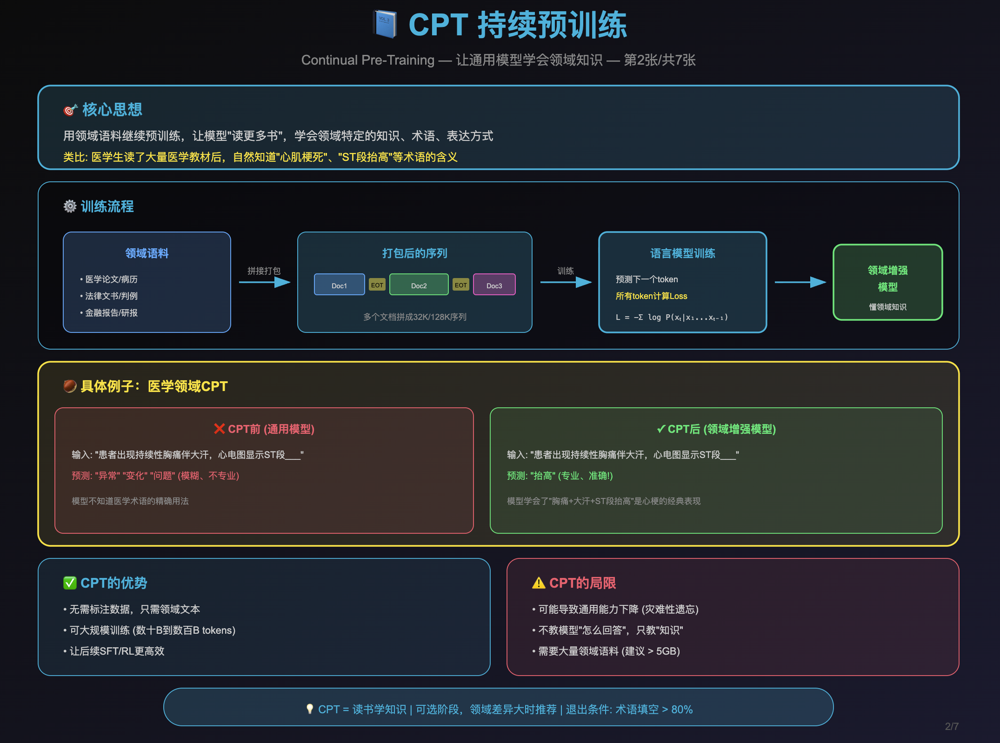

# SFT

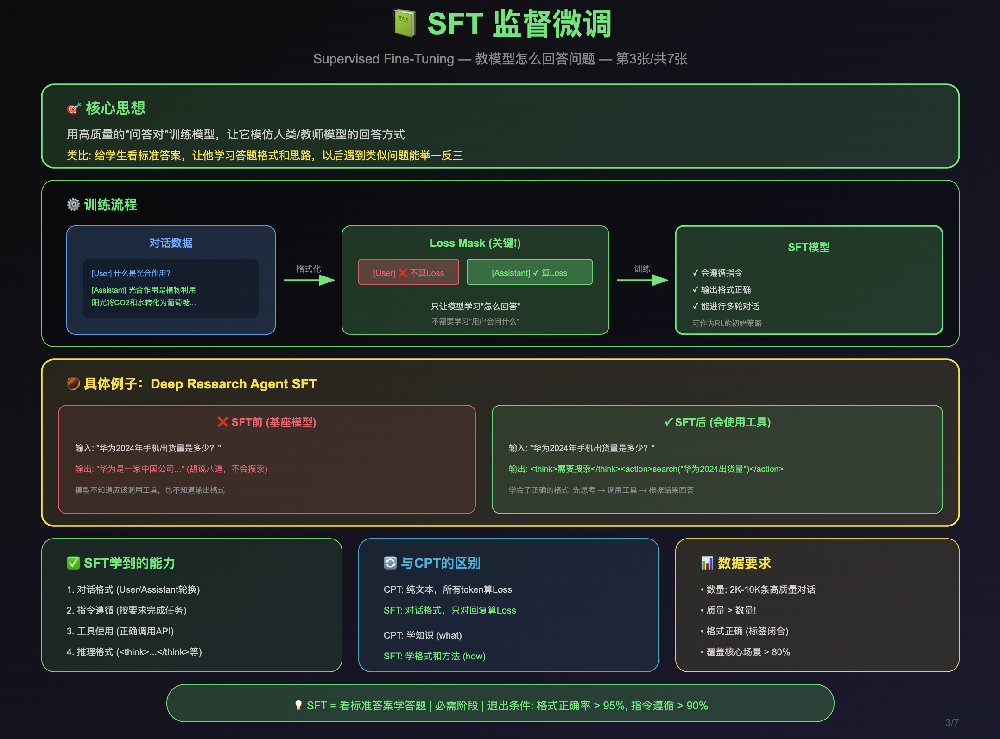

## 但是SFT只能学会应该做什么，而不能学会不应该做什么

# RL

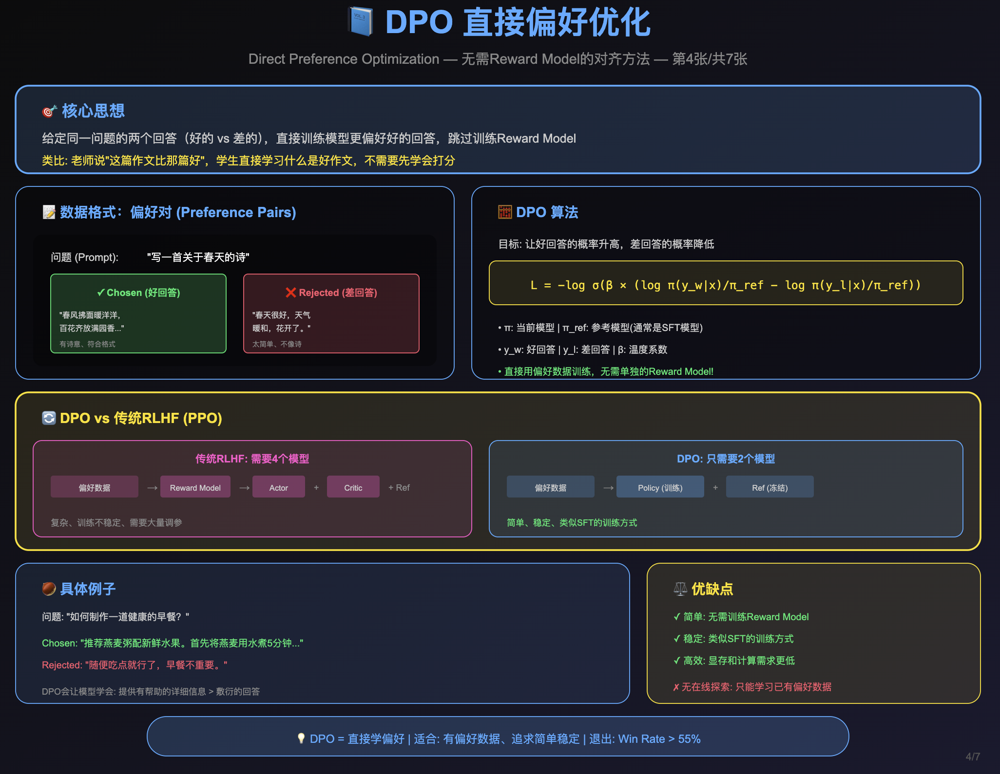

## chosen 和 rejected 是**完整独立的序列**

---

### 📊 数据采样方式

DPO 的偏好对数据通常来自以下方式：

```
Prompt: "如何制作一道健康的早餐？"

Chosen (完整回答):  "推荐燕麦粥配新鲜水果。首先将燕麦用水煮5分钟..."
Rejected (完整回答): "建议吃点面包就行了，不重要。"
```

**两个回答可以从第一个 token 开始就完全不同**，长度也可以不同。

---

### 🔢 概率计算是序列级别的

DPO 损失函数中的 $\log \pi(y|x)$ 是**整个序列的对数概率**：

$$\log \pi(y|x) = \sum_{t=1}^{T} \log \pi(y_t | x, y_{<t})$$

| 序列 | 计算内容 |
|------|---------|
| Chosen | $\log \pi(y_w\|x) = \log P(推荐\|x) + \log P(燕麦\|x,推荐) + ...$ |
| Rejected | $\log \pi(y_l\|x) = \log P(建议\|x) + \log P(吃\|x,建议) + ...$ |

---

### chosen 和 rejected **共享前缀**：

```
Chosen:   "这道菜需要先切菜，然后用中火炒5分钟"
Rejected: "这道菜需要先切菜，然后随便炒炒就行"
          ←——— 共享前缀 ———→  ←— 差异部分 —→
```

此时：
- 共享前缀部分的概率在计算时会被**相减抵消**
- 损失主要由**分叉后的差异部分**贡献

但这**不是 DPO 的要求**，只是可能出现的数据特点。

---

### 📋 常见数据来源

| 来源 | 说明 |
|------|------|
| 人工撰写 | 标注员写两个不同质量的回答 |
| 模型采样 + 人工排序 | 让模型生成多个回答，人类选最好和最差的 |
| 不同模型对比 | 强模型的输出 vs 弱模型的输出 |

---

**总结**：DPO 在**整个序列级别**优化偏好，chosen 和 rejected 是独立的完整回答，不要求有共同前缀。

**长度不一致会带来偏差**。

---

## 🎯 问题本质

$$\log \pi(y|x) = \sum_{t=1}^{T} \log P(y_t|x, y_{<t})$$

每个 token 的 $\log P < 0$，所以：

| 序列 | 长度 | log prob 特点 |
|------|------|---------------|
| Chosen | 100 tokens | 累加100个负数 → **很负** |
| Rejected | 10 tokens | 累加10个负数 → **稍负** |

**长序列天然会有更低的概率**，这可能导致模型倾向于生成短回答。

---

## 🛡️ 为什么实际中还能work？

**关键在于 log ratio 的设计**：

$$\log \frac{\pi(y|x)}{\pi_{ref}(y|x)} = \log \pi(y|x) - \log \pi_{ref}(y|x)$$

| 模型 | Chosen (长) | Rejected (短) |
|------|-------------|---------------|
| $\pi$ | -150 | -30 |
| $\pi_{ref}$ | -148 | -28 |
| **差值 (ratio)** | -2 | -2 |

两个模型对同一序列的概率变化趋势相似，**相减后长度影响被部分抵消**。

---

## ⚠️ 但问题仍然存在

实践中观察到的现象：
- DPO 训练后模型可能倾向于**生成更短的回答**
- 长度差异大的数据对会引入噪声

---

## 🔧 常见解决方案

### 1. 长度归一化
$$\log \pi(y|x) \rightarrow \frac{1}{T}\sum_{t=1}^{T} \log P(y_t|x, y_{<t})$$

### 2. 数据层面控制
构建偏好对时，保证 chosen 和 rejected **长度相近**

### 3. 算法改进
| 方法 | 特点 |
|------|------|
| **SimPO** | 引入长度归一化 + target reward margin |
| **IPO** | 不同的损失函数形式 |
| **R-DPO** | 显式添加长度正则项 |

---

# DPO属于SFT还是强化学习？？
# DPO有没有KL散度的项

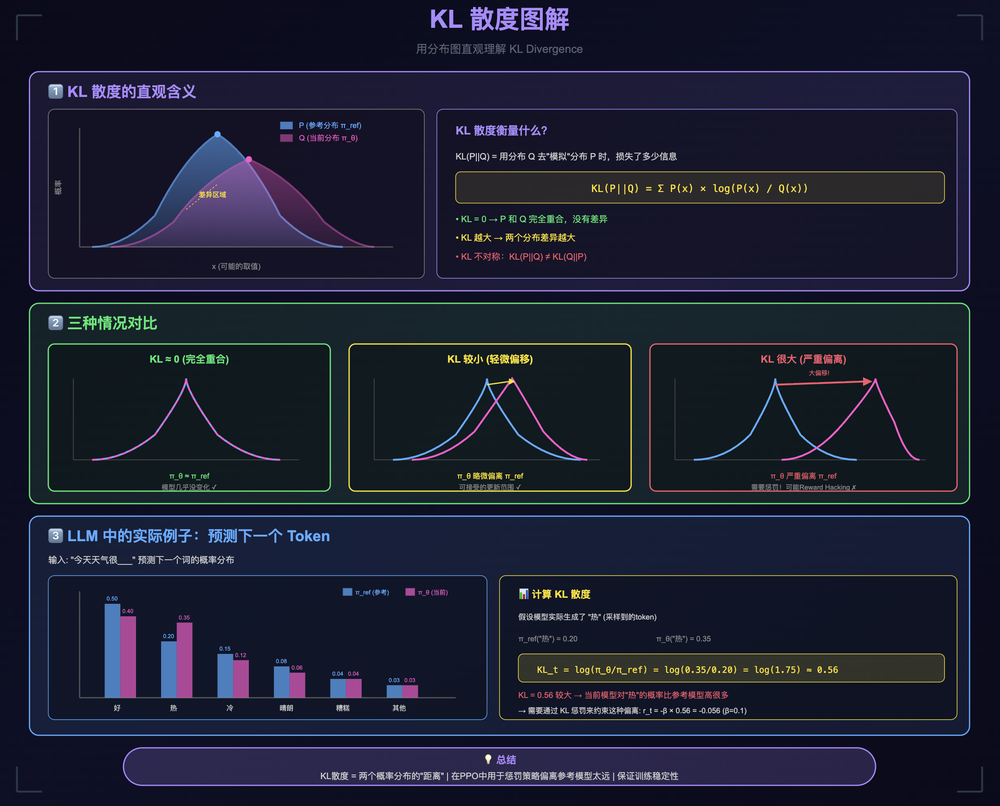

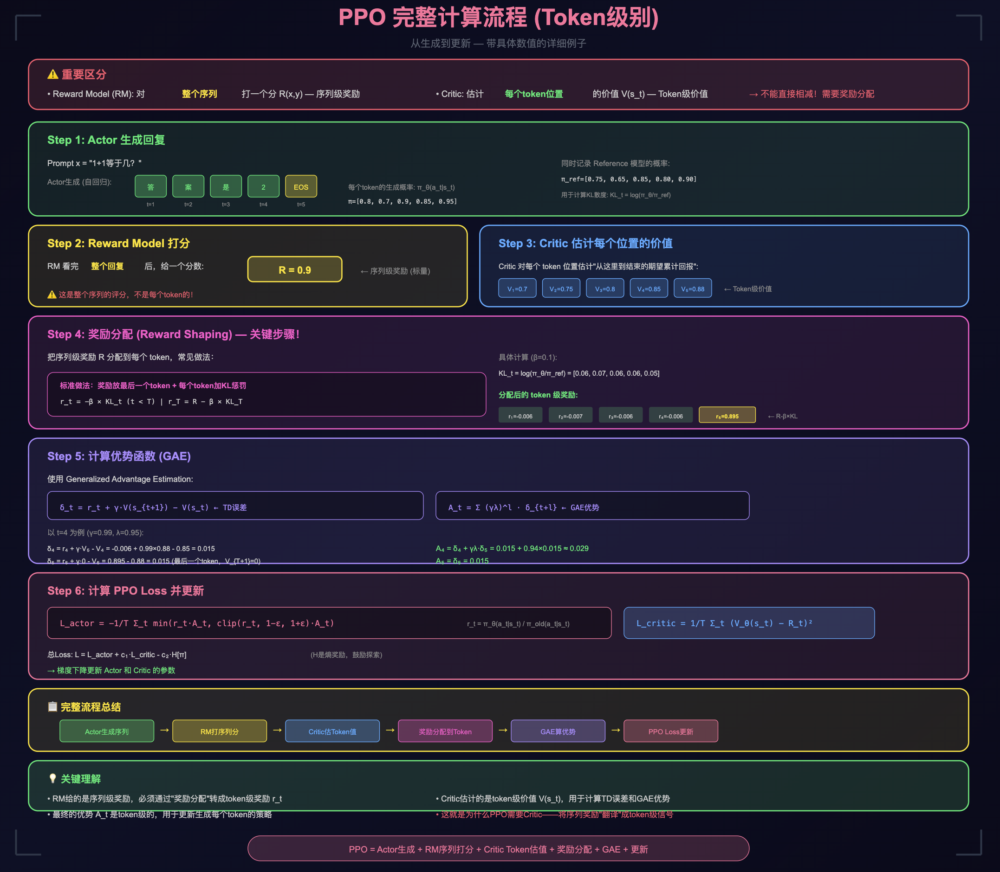

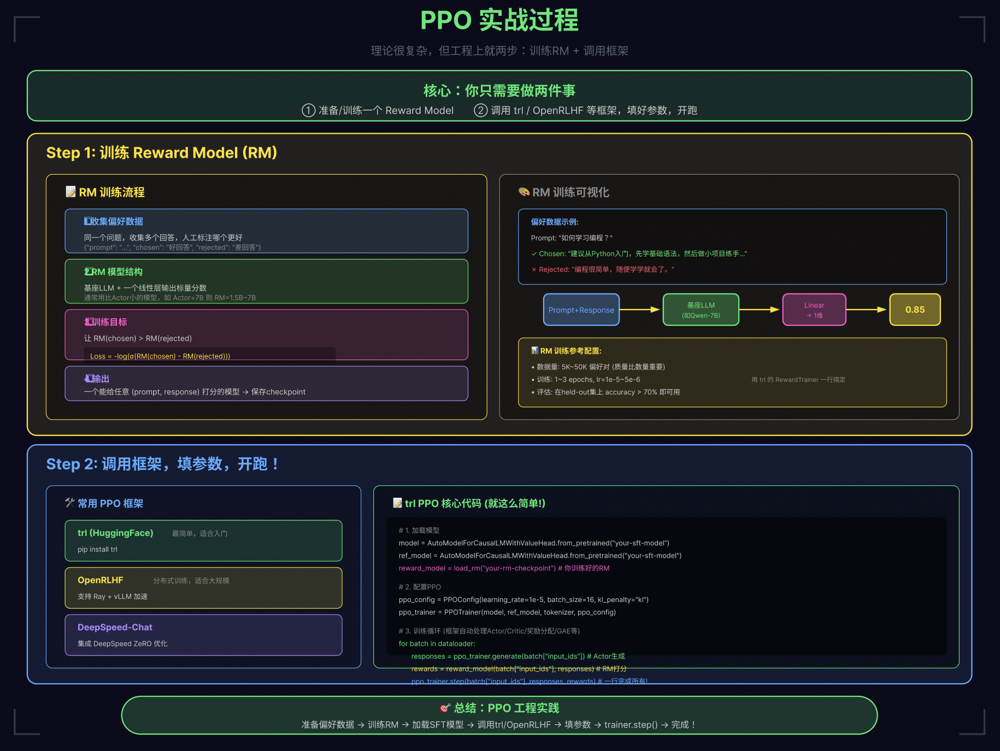

# 来看看GRPO家族

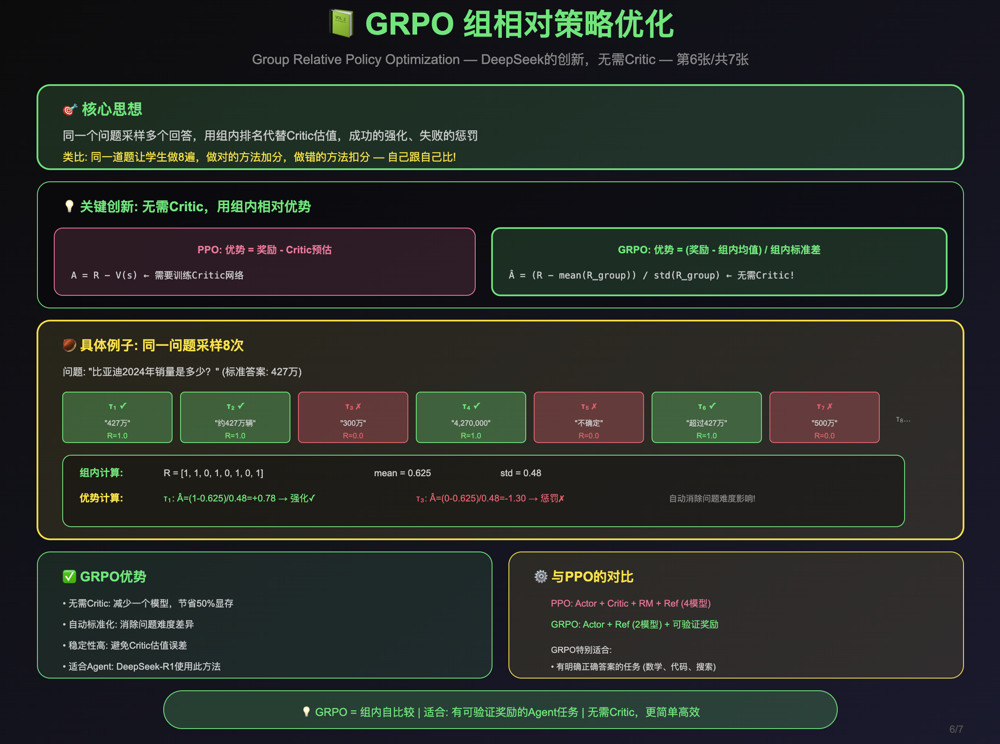

# GRPO 熵坍塌 (Entropy Collapse) 详解

---

## 什么是熵坍塌

```
训练初期:  π(y|x) = [0.2, 0.2, 0.2, 0.2, 0.2]  熵 = 1.61 ✅ 多样
    ↓
训练中期:  π(y|x) = [0.6, 0.2, 0.1, 0.05, 0.05] 熵 = 1.19
    ↓
训练后期:  π(y|x) = [0.98, 0.01, 0.01, ...]     熵 → 0 ❌ 坍塌
```

模型变得**过度自信**，只会生成几乎相同的输出。

---

## 🔍 GRPO 为什么容易熵坍塌

### 1️⃣ 组内相对比较的「马太效应」

GRPO 对同一 prompt 采样 G 个回答，计算**组内相对优势**：

$$\hat{A}_i = \frac{r_i - \text{mean}(\{r_j\})}{\text{std}(\{r_j\})}$$

| 回答 | Reward | 相对优势 | 梯度方向 |
|------|--------|----------|----------|
| A | 0.9 | +1.2 | 概率 ↑↑ |
| B | 0.7 | +0.3 | 概率 ↑ |
| C | 0.5 | -0.5 | 概率 ↓ |
| D | 0.3 | -1.0 | 概率 ↓↓ |

**即使所有回答都不错，也必须有输家！**

---

### 2️⃣ 正反馈循环

```
┌─────────────────────────────────────────┐
│  A 的概率高 → 采样时 A 更常出现           │
│       ↓                                  │
│  组内比较时 A 经常获胜                    │
│       ↓                                  │
│  A 的优势被进一步强化                     │
│       ↓                                  │
│  A 的概率更高 → 循环加剧                  │
└─────────────────────────────────────────┘
```

---

### 3️⃣ 采样多样性下降

| 训练阶段 | 采样结果 (G=4) | 问题 |
|----------|---------------|------|
| 初期 | [A, B, C, D] | 多样，比较有意义 |
| 中期 | [A, A, B, A] | A 占主导 |
| 后期 | [A, A, A, A] | 全是 A，无法学习 |

**当采样缺乏多样性时**：
- 组内 std → 0
- 优势估计变得不稳定
- 梯度信号退化

---

### 4️⃣ KL 约束不足以阻止

$$J = \mathbb{E}[\hat{A}] - \beta \cdot KL(\pi \| \pi_{ref})$$

| 问题 | 说明 |
|------|------|
| β 太小 | KL 惩罚不够，模型快速偏离 |
| β 太大 | 学习太慢，但也不能完全阻止 |
| 根本问题 | KL 只约束与 ref 的距离，**不直接约束熵** |

---

## 熵坍塌的后果

| 后果 | 表现 |
|------|------|
| **模式单一** | 所有问题都用类似套路回答 |
| **探索停止** | 无法发现更好的解法 |
| **泛化变差** | 新问题上表现下降 |
| **推理僵化** | 思维链变得模板化 |


**核心矛盾**：GRPO 的目标是找到最优策略，但过度优化会牺牲多样性——这是强化学习中 **exploitation vs exploration** 的经典权衡。

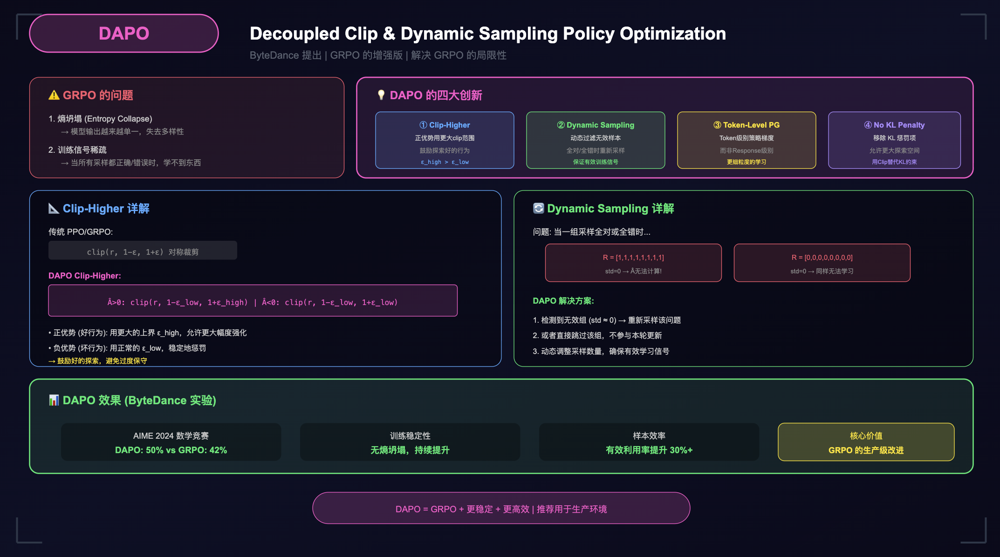

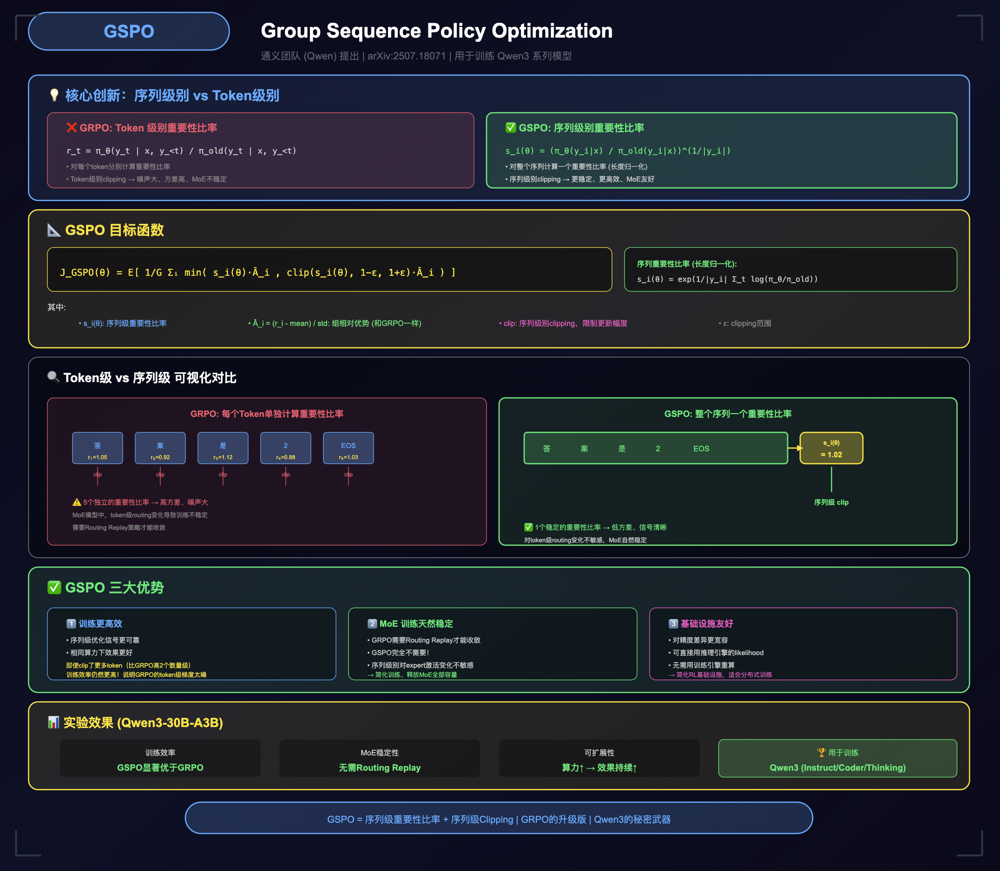

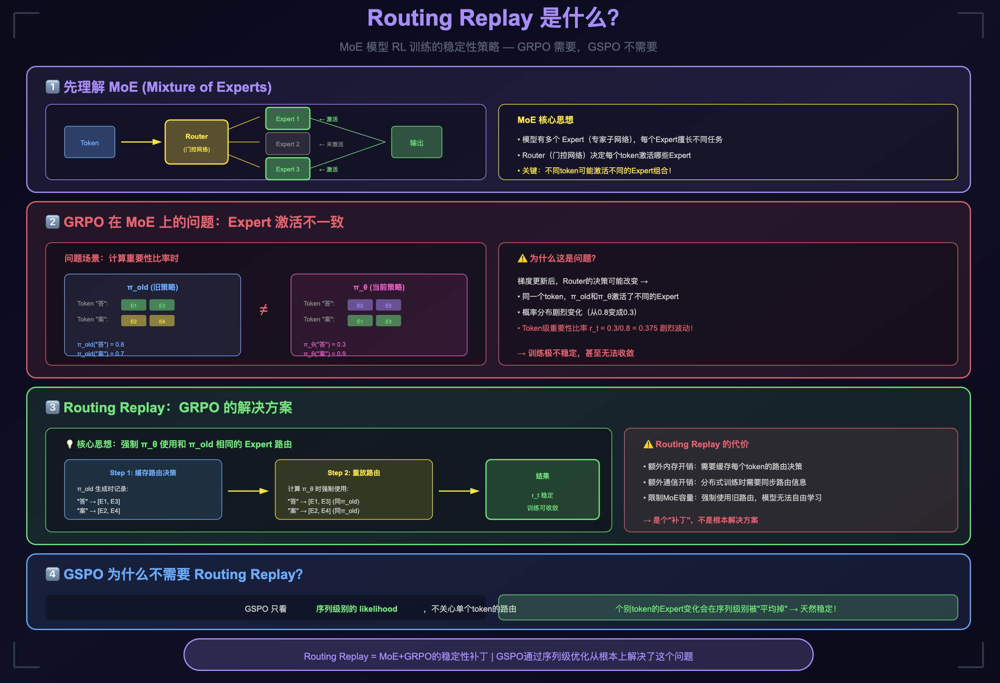

# 统一看一下不同阶段的训练

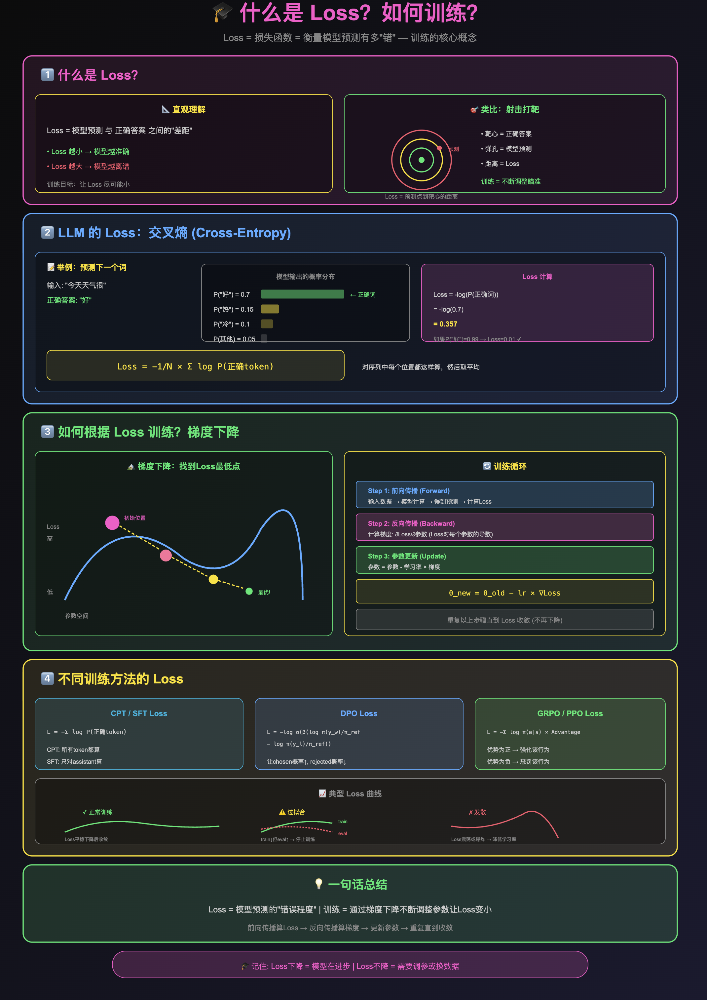

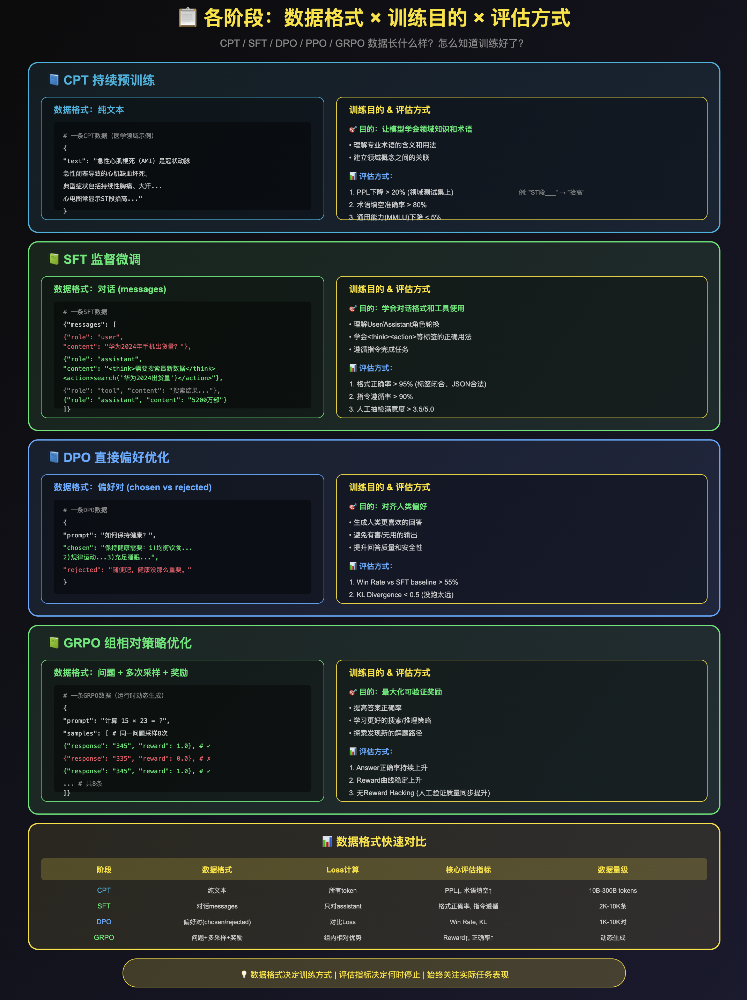